# 🐦 Cantos de Aves — TinyML · Entrenamiento (Metodología KWS)

Pipeline idéntico al Ejercicio KWS (helios/tennis/poker), ahora con **6 clases de aves + 1 clase `ave-no-registrada`** (música, ruido exterior, voces y aves que no están en la lista):
1. Cargar audios → recorte de 1 s con más energía
2. **MFCC a mano en numpy** (ventana 25 ms, salto 10 ms, 40 filtros mel, log antes de la DCT, 13 coeficientes)
3. Aplanado a 1.274 features
4. **Experimento A** (split aleatorio — con trampa de fuga) vs **Experimento B** (leave-one-session-out — honesto)
5. Export del modelo para la app (`modelo_aves.zip`) — tfjs + labels

**Antes de correr:** arrastra **los dos zips** (`dataset_aves_nano.zip` y `dataset_no_aves.zip`, ya renombrados con `_S<n>_`) al panel de archivos 📁 y dale **Entorno de ejecución → Ejecutar todo**. La celda 2 lo descomprime sola.

In [1]:
import zipfile, io, os, glob, wave
import numpy as np
import matplotlib.pyplot as plt

SR = 16000
VENTANA = 25e-3          # 25 ms (400 muestras @16k)
SALTO = 10e-3            # 10 ms (160 muestras @16k)
N_MEL = 40
N_COEFS = 13
N_MUESTRAS_UTILES = 16000          # ventana de análisis: 1 s
FRAMES = 98                        # 25 ms/10 ms sobre 1 s → 98 frames
N_FEATURES = FRAMES * N_COEFS      # 1.274  (igual que el KWS)
N_MUESTRAS_APP = FRAMES * 160      # 15.680: el mismo recorte que hace la app (js/app.js)
BASE = '/content' if os.path.isdir('/content') else os.getcwd()   # Colab o PC local

CLASES = ['garrapatero-comun','pellar-comun','pigua','bichofue-griton','azulejo-comun','lora-andina',
          'ave-no-registrada']   # 7.ª clase: todo lo que NO es una de las 6 aves (música, ruido, otras aves)
NO_REG = CLASES.index('ave-no-registrada')
print('CLASES:', CLASES, '| features por ejemplo:', N_FEATURES)

CLASES: ['garrapatero-comun', 'pellar-comun', 'pigua', 'bichofue-griton', 'azulejo-comun', 'lora-andina', 'ave-no-registrada'] | features por ejemplo: 1274


## 1 · Datos
Opción A: URL directa del zip (Drive con permiso 'cualquiera con el enlace' → usar el enlace `uc?export=download&id=...`).  
Opción B: arrastrar el zip al panel de archivos (icono 📁 a la izquierda) y dejar `DATA_URL = None`.

In [2]:
DATA_URL = None   # opcional: 'https://drive.google.com/uc?export=download&id=XXXXXXXX'
DATA_DIR = os.path.join(BASE, 'data')

if DATA_URL:
    !wget -q -O "{BASE}/dataset_aves.zip" "{DATA_URL}"

# Descomprime cualquier .zip que hayas subido (panel 📁) en data/
for z in glob.glob(os.path.join(BASE, '*.zip')):
    if 'modelo_aves' in z: continue
    with zipfile.ZipFile(z) as f: f.extractall(DATA_DIR)
    print('📦 descomprimido:', os.path.basename(z))

rutas = sorted(glob.glob(os.path.join(DATA_DIR, '**', '*.wav'), recursive=True))
print('audios encontrados:', len(rutas))
print(rutas[:3] if rutas else '⚠️ ¡Sin audios! Arrastra dataset_aves_nano.zip al panel 📁 y vuelve a correr esta celda')

📦 descomprimido: dataset_aves_nano.zip


📦 descomprimido: dataset_no_aves.zip
audios encontrados: 184
['/tmp/claude-1000/-home-sebitas/d693743d-3d77-4ba1-87c6-009ab7a773a1/scratchpad/entreno/data/dataset_aves/azulejo-comun/azulejo-comun_S1_01.wav', '/tmp/claude-1000/-home-sebitas/d693743d-3d77-4ba1-87c6-009ab7a773a1/scratchpad/entreno/data/dataset_aves/azulejo-comun/azulejo-comun_S1_02.wav', '/tmp/claude-1000/-home-sebitas/d693743d-3d77-4ba1-87c6-009ab7a773a1/scratchpad/entreno/data/dataset_aves/azulejo-comun/azulejo-comun_S1_03.wav']


## 2 · Cargar + recorte por energía
Audios de 3–5 s → nos quedamos con la **ventana de 1 s con más energía** (los cantos no ocupan todo el clip). Remuestreo por decimación lineal si hace falta (Edge Impulse exporta a 16 kHz mono, igual que el KWS).

In [3]:
def cargar_wav(ruta):
    w = wave.open(ruta, 'rb')
    sr = w.getframerate(); n = w.getnframes(); ch = w.getnchannels()
    x = np.frombuffer(w.readframes(n), dtype=np.int16).astype(np.float64)
    w.close()
    if ch > 1: x = x.reshape(-1, ch).mean(axis=1)
    if sr != SR:  # remuestreo lineal simple
        x = np.interp(np.linspace(0, len(x)-1, int(len(x)*SR/sr)), np.arange(len(x)), x)
    return x / (np.abs(x).max() + 1e-9)

def recorte_energia(x, n=N_MUESTRAS_UTILES):
    if len(x) <= n: return np.pad(x, (0, n-len(x)))
    paso = 1000
    energias = [np.sum(x[i:i+n]**2) for i in range(0, len(x)-n, paso)]
    i = int(np.argmax(energias)) * paso
    return x[i:i+n]

def clase_desde_ruta(ruta):
    for c in CLASES:
        if c in ruta: return c
    return None

def sesion_desde_ruta(ruta):
    import re
    m = re.search(r'_S(\d+)_', ruta)
    return int(m.group(1)) if m else None

def recorte_app(x, n=N_MUESTRAS_APP):
    """Copia exacta de recorteEnergia() de js/app.js: empieza en el bloque de 1000
    muestras con más energía y toma 15.680 muestras. Así el modelo ve lo mismo en la app."""
    if len(x) <= n: return np.pad(x, (0, n-len(x)))
    paso = 1000
    energias = [np.sum(x[i:i+paso:4]**2) for i in range(0, len(x)-paso+1, paso)]
    i = int(np.argmax(energias)) * paso
    return x[i:i+n]

X, AUDIOS, y, sesiones, rutas_ok = [], [], [], [], []
for r in rutas:
    c = clase_desde_ruta(r)
    if c is None or sesion_desde_ruta(r) is None:
        print('⏭️ sin clase/sesión:', r); continue
    a = cargar_wav(r); AUDIOS.append(a)
    X.append(recorte_energia(a))
    y.append(CLASES.index(c)); sesiones.append(sesion_desde_ruta(r)); rutas_ok.append(r)
X = np.array(X).astype(np.float32); y = np.array(y); sesiones = np.array(sesiones)
print('✅ cargados:', X.shape, '| por clase:', {c:int((y==i).sum()) for i,c in enumerate(CLASES)})
print('sesiones:', sorted(set(sesiones.tolist())))

✅ cargados: (184, 16000) | por clase: {'garrapatero-comun': 15, 'pellar-comun': 15, 'pigua': 16, 'bichofue-griton': 15, 'azulejo-comun': 15, 'lora-andina': 15, 'ave-no-registrada': 93}
sesiones: [1, 2, 3]


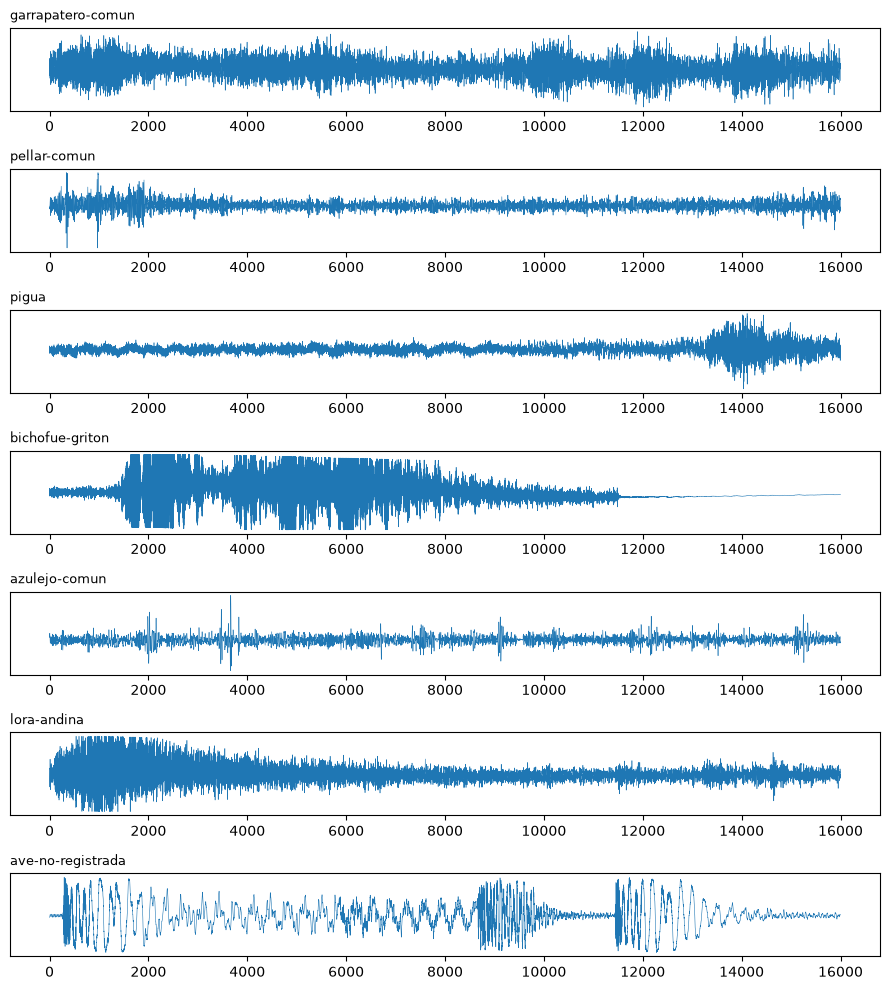

In [4]:
# Exploratoria: un audio por clase
fig, axs = plt.subplots(len(CLASES), 1, figsize=(9, 10))
for i, c in enumerate(CLASES):
    idx = np.where(y == i)[0][0]
    axs[i].plot(X[idx], lw=.4); axs[i].set_title(c, fontsize=9, loc='left'); axs[i].set_yticks([])
plt.tight_layout(); plt.savefig('exploratoria_aves.png', dpi=110)

## 3 · MFCC a mano en numpy (lo mismo del KWS)
Pre-énfasis → frames (25/10 ms) → ventana de Hann → FFT → filtrobank mel (40) → **log antes de la DCT** → DCT → 13 coeficientes.

✅ features: (184, 1274)


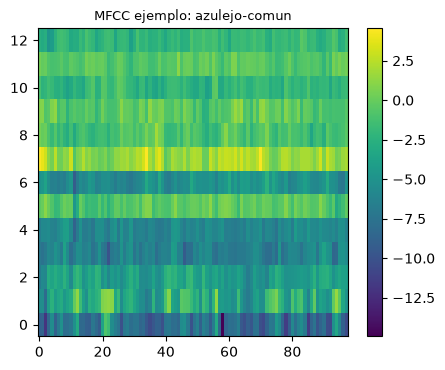

In [5]:
def hz_a_mel(f):  return 2595 * np.log10(1 + f / 700)
def mel_a_hz(m):  return 700 * (10**(m / 2595) - 1)

def filtrobank_mel(sr=SR, n_fft=512, n_mel=N_MEL, fmin=50, fmax=8000):
    mel_pts = np.linspace(hz_a_mel(fmin), hz_a_mel(fmax), n_mel + 2)
    bins = np.floor((n_fft + 1) * mel_a_hz(mel_pts) / sr).astype(int)
    fb = np.zeros((n_mel, n_fft // 2 + 1))
    for m in range(1, n_mel + 1):
        izq, ctr, der = bins[m-1], bins[m], bins[m+1]
        if ctr == izq: ctr += 1
        if der == ctr: der += 1
        fb[m-1, izq:ctr] = (np.arange(izq, ctr) - izq) / (ctr - izq)
        fb[m-1, ctr:der] = 1 - (np.arange(ctr, der) - ctr) / (der - ctr)
    return fb

FB = filtrobank_mel()
DCT_MAT = np.fromfunction(lambda k, n: np.cos(np.pi * k * (2*n+1) / (2*N_MEL)),
                          (N_COEFS, N_MEL)) * np.sqrt(2/N_MEL)
DCT_MAT[0] *= np.sqrt(1/2)

def mfcc(x, sr=SR):
    x = np.append(x[0], x[1:] - 0.97 * x[:-1])                # pre-énfasis
    L, n_fft = len(x), 512
    frame, hop = int(VENTANA*sr), int(SALTO*sr)
    n_frames = 1 + (L - frame) // hop
    hann = 0.5 - 0.5*np.cos(np.linspace(0, 2*np.pi, frame, endpoint=False))
    frames = np.lib.stride_tricks.sliding_window_view(x, frame)[::hop][:n_frames] * hann
    # STFT
    mag = np.abs(np.fft.rfft(frames, n_fft, axis=1))**2
    mel = np.log(mag @ FB.T + 1e-10)                          # log ANTES de la DCT
    return (mel @ DCT_MAT.T)[:, :N_COEFS]                     # (n_frames, 13)

def features(x):
    m = mfcc(recorte_app(x))      # mismo recorte que js/app.js → 96 frames + 2 de ceros
    if m.shape[0] < FRAMES: m = np.vstack([m, np.zeros((FRAMES - m.shape[0], N_COEFS))])
    return m[:FRAMES].flatten()                                # 1.274

F = np.stack([features(a) for a in AUDIOS]).astype(np.float32)
print('✅ features:', F.shape)
plt.figure(figsize=(5,4)); plt.imshow(mfcc(X[0]).T, aspect='auto', origin='lower');
plt.title('MFCC ejemplo: ' + CLASES[y[0]], fontsize=9); plt.colorbar()

## 4 · Modelo — MLP en puro numpy (mismo estilo del KWS)
1274 → 64 (ReLU) → 7 (softmax) · cross-entropy **con peso por clase** (la clase `ave-no-registrada` tiene más clips que cada ave) · mini-batches.

In [6]:
def inicializar(n_in=N_FEATURES, oc=64, n_out=len(CLASES), semilla=0):
    rng = np.random.default_rng(semilla)
    W1 = rng.normal(0, np.sqrt(2/n_in), (n_in, oc)).astype(np.float32)
    b1 = np.zeros(oc, np.float32)
    W2 = rng.normal(0, np.sqrt(2/oc), (oc, n_out)).astype(np.float32)
    b2 = np.zeros(n_out, np.float32)
    return {'W1':W1,'b1':b1,'W2':W2,'b2':b2}

def forward(m, X, entrenar=False):
    z1 = X @ m['W1'] + m['b1']; a1 = np.maximum(z1, 0)
    z2 = a1 @ m['W2'] + m['b2']
    z2 -= z2.max(axis=1, keepdims=True)
    p = np.exp(z2); p /= p.sum(axis=1, keepdims=True)
    cache = (X, z1, a1, p) if entrenar else None
    return p, cache

def entrenar(m, Xtr, ytr, epocas=60, bs=16, lr=1e-2, semilla=0):
    rng = np.random.default_rng(semilla); n = len(Xtr)
    # peso por clase = n / (k · conteo): cada clase pesa lo mismo aunque tenga más clips
    conteo = np.bincount(ytr, minlength=len(CLASES)).astype(np.float32)
    w_clase = np.where(conteo > 0, n / (len(CLASES) * np.maximum(conteo, 1)), 0).astype(np.float32)
    hist = []
    for ep in range(epocas):
        idx = rng.permutation(n)
        for i in range(0, n, bs):
            b = idx[i:i+bs]
            Xb, yb = Xtr[b], ytr[b]
            p, (Xi, z1, a1, _) = forward(m, Xb, entrenar=True)
            dz2 = p.copy(); dz2[np.arange(len(b)), yb] -= 1
            dz2 *= w_clase[yb][:, None]
            dz2 /= len(b)
            dW2 = a1.T @ dz2; db2 = dz2.sum(0)
            da1 = dz2 @ m['W2'].T
            dz1 = da1 * (z1 > 0)
            dW1 = Xi.T @ dz1; db1 = dz1.sum(0)
            m['W2'] -= lr*dW2; m['b2'] -= lr*db2
            m['W1'] -= lr*dW1; m['b1'] -= lr*db1
        # pérdida y acc de train
        ptr, _ = forward(m, Xtr)
        plog = -np.log(ptr[np.arange(n), ytr] + 1e-9).mean()
        hist.append((ep, float(plog)))
    return hist

def exactitud(m, X, y):
    p, _ = forward(m, X)
    return float((p.argmax(1) == y).mean()), p

## 5 · Experimento A — split aleatorio (con la trampa)
Mezcla **todo** al azar y separa 80/20. Clips vecinos de una misma sesión caen en ambos lados: la red aprende el "brillo" de la sesión, no el canto. Espera un número **demasiado bonito**.

In [7]:
def media_desv(F):
    mu, sd = F.mean(0), F.std(0) + 1e-6
    # c0 = energía del frame: cambia con el volumen/distancia del micrófono, no con el ave.
    # La app no normaliza el volumen, así que lo anulamos (sd enorme → feature ≈ 0).
    sd[0::N_COEFS] = 1e6
    return mu, sd

rng = np.random.default_rng(0)
idx = rng.permutation(len(F)); n_tr = int(.8*len(F))
trA, teA = idx[:n_tr], idx[n_tr:]
mu, sd = media_desv(F[trA])
mA = inicializar(semilla=1)
histA = entrenar(mA, (F[trA]-mu)/sd, y[trA])
accA, _ = exactitud(mA, (F[teA]-mu)/sd, y[teA])
print(f'🅰️ Experimento A (split aleatorio): exactitud = {accA*100:.1f}%  ← ¡demasiado bonita?')
# ¿de qué sesiones viene el test? → fuga
ses_tr, ses_te = set(sesiones[trA].tolist()), set(sesiones[teA].tolist())
print(f'   sesiones compartidas entre train y test: {sorted(ses_tr & ses_te)}  ← fuga de datos si hay cruce')

🅰️ Experimento A (split aleatorio): exactitud = 94.6%  ← ¡demasiado bonita?
   sesiones compartidas entre train y test: [1, 2, 3]  ← fuga de datos si hay cruce


## 6 · Experimento B — leave-one-session-out (honesto)
Entrena con **todas** las sesiones menos una, prueba con la sesión dejada fuera, y rota. El promedio es la métrica real.

  deja fuera sesión S1: prueba sobre 64 clips → 68.8%


  deja fuera sesión S2: prueba sobre 63 clips → 54.0%


  deja fuera sesión S3: prueba sobre 57 clips → 63.2%

🅱️ Experimento B (leave-one-session-out): 62.0%  ← la métrica honesta
   caída A→B: 32.6 puntos = la fuga de sesión del Experimento A


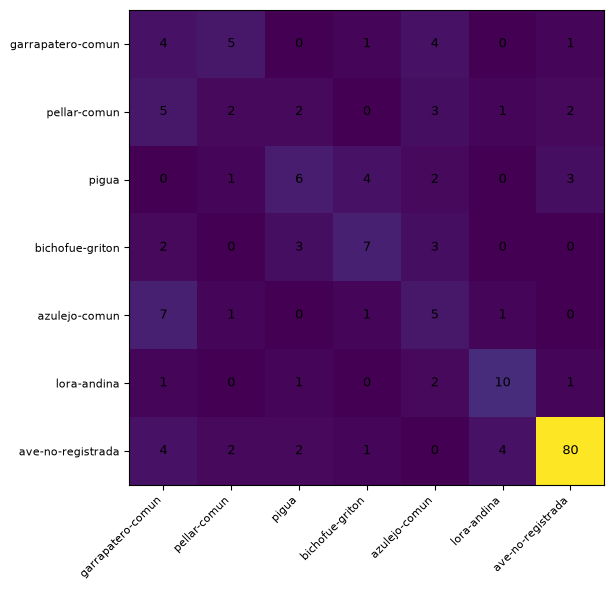

In [8]:
sesiones_unicas = sorted(set(sesiones.tolist()))
accs, matrices = [], np.zeros((len(CLASES), len(CLASES)), int)
probsB, yB = [], []   # para medir el umbral de la app
for s_out in sesiones_unicas:
    tr, te = sesiones != s_out, sesiones == s_out
    mu, sd = media_desv(F[tr])
    mB = inicializar(semilla=1)
    entrenar(mB, (F[tr]-mu)/sd, y[tr])
    acc, p = exactitud(mB, (F[te]-mu)/sd, y[te])
    accs.append(acc)
    probsB.append(p); yB.append(y[te])
    pred = p.argmax(1)
    for t, pr in zip(y[te], pred): matrices[t, pr] += 1
    print(f'  deja fuera sesión S{s_out}: prueba sobre {int(te.sum())} clips → {acc*100:.1f}%')
accB = float(np.mean(accs))
print(f'\n🅱️ Experimento B (leave-one-session-out): {accB*100:.1f}%  ← la métrica honesta')
print(f'   caída A→B: {(accA-accB)*100:.1f} puntos = la fuga de sesión del Experimento A')

fig, ax = plt.subplots(figsize=(7,6))
K = len(CLASES)
im = ax.imshow(matrices); ax.set_xticks(range(K), CLASES, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(K), CLASES, fontsize=8)
for i in range(K):
    for j in range(K): ax.text(j, i, matrices[i,j], ha='center', va='center', fontsize=9)
plt.tight_layout(); plt.savefig('matriz_confusion_B.png', dpi=110)

## 6b · ¿Cuándo decir "Ave no registrada"?
La app dice **🚫 Ave no registrada** si gana la clase `ave-no-registrada` **o** si la mejor ave no pasa el umbral de confianza (40 %). Medimos con las predicciones honestas del Experimento B cuánto acepta de aves reales y cuánto rechaza de lo que no es ave.

In [9]:
UMBRAL = 0.40   # el mismo de js/app.js
P, Y = np.vstack(probsB), np.concatenate(yB)
pred, conf = P.argmax(1), P.max(1)
rechaza = (pred == NO_REG) | (conf < UMBRAL)
ave = Y != NO_REG
print(f'umbral {UMBRAL:.0%}')
print(f'  lo que NO es ave → dice "Ave no registrada": {rechaza[~ave].mean()*100:.1f}%  ({(~ave).sum()} clips)')
print(f'  aves registradas → aceptadas y bien nombradas: {((~rechaza) & (pred == Y))[ave].mean()*100:.1f}%')
print(f'  aves registradas → rechazadas por el umbral:    {rechaza[ave].mean()*100:.1f}%')
for u in (0.4, 0.5, 0.6, 0.7, 0.8):
    r = (pred == NO_REG) | (conf < u)
    print(f'   u={u:.1f}: no-ave rechazado {r[~ave].mean()*100:5.1f}% | aves aceptadas bien {((~r) & (pred == Y))[ave].mean()*100:5.1f}%')


umbral 40%
  lo que NO es ave → dice "Ave no registrada": 87.1%  (93 clips)
  aves registradas → aceptadas y bien nombradas: 34.1%
  aves registradas → rechazadas por el umbral:    17.6%
   u=0.4: no-ave rechazado  87.1% | aves aceptadas bien  34.1%
   u=0.5: no-ave rechazado  87.1% | aves aceptadas bien  30.8%
   u=0.6: no-ave rechazado  88.2% | aves aceptadas bien  25.3%
   u=0.7: no-ave rechazado  91.4% | aves aceptadas bien  18.7%
   u=0.8: no-ave rechazado  92.5% | aves aceptadas bien  15.4%


## 7 · Export para la app (tfjs + labels)
Pasamos el numpy a Keras/TF con los **mismos pesos**, y exportamos para el navegador. Descarga `modelo_aves.zip` y descomprímelo en `app/modelo/`.

In [10]:
# Entrenamos el modelo final con TODOS los datos (sesiones combinadas) ya validado por B
mu_full, sd_full = media_desv(F)
mF = inicializar(semilla=1)
entrenar(mF, (F-mu_full)/sd_full, y, epocas=80)
accF, _ = exactitud(mF, (F-mu_full)/sd_full, y)
print(f'modelo final sobre todo el train: {accF*100:.1f}%')
np.savez('params_final.npz', W1=mF['W1'], b1=mF['b1'], W2=mF['W2'], b2=mF['b2'], mu=mu_full, sd=sd_full)

modelo final sobre todo el train: 100.0%


In [11]:
# Export a TensorFlow.js (formato layers-model) escrito con numpy: sin instalar TensorFlow,
# así no hay choques de versiones en Colab. Son los MISMOS pesos del MLP.
import json, shutil
p = np.load('params_final.npz')
OUT = os.path.join(BASE, 'modelo_export')
shutil.rmtree(OUT, ignore_errors=True); os.makedirs(OUT)

def densa(nombre, unidades, activacion, entrada=None):
    cfg = {'name': nombre, 'trainable': True, 'dtype': 'float32', 'units': unidades,
           'activation': activacion, 'use_bias': True,
           'kernel_initializer': {'class_name': 'GlorotUniform', 'config': {'seed': None}},
           'bias_initializer': {'class_name': 'Zeros', 'config': {}},
           'kernel_regularizer': None, 'bias_regularizer': None, 'activity_regularizer': None,
           'kernel_constraint': None, 'bias_constraint': None}
    if entrada: cfg['batch_input_shape'] = [None, entrada]
    return {'class_name': 'Dense', 'config': cfg}

pesos = [('dense/kernel', p['W1']), ('dense/bias', p['b1']),
         ('dense_1/kernel', p['W2']), ('dense_1/bias', p['b2'])]
with open(os.path.join(OUT, 'group1-shard1of1.bin'), 'wb') as f:
    for _, w in pesos: f.write(np.ascontiguousarray(w, dtype='<f4').tobytes())

modelo_json = {
    'format': 'layers-model', 'generatedBy': 'numpy (notebook aves)', 'convertedBy': None,
    'modelTopology': {'class_name': 'Sequential', 'keras_version': '2.15.0', 'backend': 'tensorflow',
        'config': {'name': 'aves_mlp', 'layers': [
            densa('dense', 64, 'relu', entrada=N_FEATURES),
            densa('dense_1', len(CLASES), 'softmax')]}},
    'weightsManifest': [{'paths': ['group1-shard1of1.bin'],
        'weights': [{'name': n, 'shape': list(w.shape), 'dtype': 'float32'} for n, w in pesos]}]}
with open(os.path.join(OUT, 'model.json'), 'w') as f: json.dump(modelo_json, f)
with open(os.path.join(OUT, 'labels.json'), 'w') as f:
    json.dump({'clases': CLASES, 'features': N_FEATURES, 'frames': FRAMES, 'coefs': N_COEFS,
               'sr': SR, 'mu': p['mu'].tolist(), 'sd': p['sd'].tolist()}, f)

# zip con los 3 archivos en la raíz → se descomprime directo en app/modelo/
ZIP = os.path.join(BASE, 'modelo_aves.zip')
with zipfile.ZipFile(ZIP, 'w', zipfile.ZIP_DEFLATED) as z:
    for nombre in sorted(os.listdir(OUT)): z.write(os.path.join(OUT, nombre), nombre)
print('archivos:', sorted(os.listdir(OUT)))
try:
    from google.colab import files
    files.download(ZIP)
    print('✅ descarga modelo_aves.zip → descomprímelo en app/modelo/')
except ImportError:
    print('✅ modelo listo en', ZIP, '→ descomprímelo en app/modelo/')

archivos: ['group1-shard1of1.bin', 'labels.json', 'model.json']
✅ modelo listo en /tmp/claude-1000/-home-sebitas/d693743d-3d77-4ba1-87c6-009ab7a773a1/scratchpad/entreno/modelo_aves.zip → descomprímelo en app/modelo/
